# CardSeedDuel — Approccio B con ResNet18 congelata

**Obiettivo:** capire se una ResNet18 pre-addestrata su ImageNet rende il problema "troppo facile".
Se la baseline puramente neurale arriva già vicino al 100% con il 20% dei dati, il vantaggio di DeepProbLog rischia di non vedersi (effetto soffitto).

**Modello (Approccio B, solo rete neurale, nessuna logica):**
```
img1 ─► ResNet18 congelata (ImageNet, fc rimosso) ─► f1 (512) ┐
                                                              ├─► concat (1024) ─► Linear 256 ─► ReLU ─► Dropout ─► Linear 3 ─► {p1_win, p2_win, draw}
img2 ─► stessa ResNet18 (pesi condivisi)          ─► f2 (512) ┘
```
- **Nessun fine-tuning:** il backbone non viene mai aggiornato e resta in `eval()` (BatchNorm fissa). Si allena solo la nuova testa.
- **Input:** JPEG nativi 224×224 RGB, normalizzazione ImageNet, nessun resize o crop (il `CenterCrop` di `weights.transforms()` taglierebbe i bordi della carta).
- **Supervisione:** solo l'esito della partita, come richiesto per l'Approccio B. Le etichette dei semi si usano solo per controlli e diagnostica.
- **Dati:** coppie generate dalla pipeline del PR #18 (run finale `20261116T234548Z_35065d09`), lette direttamente dal repo GitHub: train al **20%** (6.000 coppie), al **50%** (15.000) e al **100%** (30.000), subset annidati, valid e test fissi (3.000 + 3.000).
- **Protocollo:** Adam lr 1e-3, batch 32, early stopping su Macro-F1 di validation, checkpoint migliore su valid, valutazione finale sul test. Si usano 3 seed per percentuale.

**Cosa succede, in ordine:**
1. Si carica la ResNet18 con i pesi ImageNet.
2. Si toglie la sua testa (`fc`, 512 → 1000 classi ImageNet) e la si sostituisce con `Identity`: ogni carta diventa un vettore da 512.
3. Si congela il backbone (niente gradienti, `eval()`): **resta congelato per tutto il notebook, non viene mai sbloccato**.
4. Si crea la nuova testa `DuelHead` (concat di due vettori → MLP → 3 esiti), l'unica parte che si allena.
5. Per ogni percentuale e seed: training della sola testa con early stopping su valid, poi si ricarica il checkpoint migliore.
6. Inferenza sul test: backbone congelato + testa allenata → esito previsto per ogni coppia.

**Ottimizzazione:** il backbone è congelato, quindi le feature di ogni immagine non cambiano mai. Le calcoliamo **una sola volta** e alleniamo la testa sulle feature salvate. Il risultato è identico a quello che si otterrebbe facendo passare ogni volta le immagini nella ResNet, ma molto più veloce. I tempi di estrazione e di training sono riportati separatamente.

> **Come eseguirlo:** *Runtime → Cambia tipo di runtime → GPU (T4)*, poi *Runtime → Esegui tutto* (circa 3-4 minuti).
> Non serve Drive né alcuno zip: la prima cella clona il repo pubblico (immagini e coppie sono versionati in `main`).
> Funziona anche su CPU, ma l'estrazione delle feature è più lenta. Descrizione completa e risultati: `notebooks/README_approccio_B_resnet18_frozen.md`.

## 1. Configurazione e dati dal repo GitHub

In [ ]:
import os, sys, time, subprocess

# Immagini e coppie sono versionate nel repo pubblico: niente Drive, niente zip.
REPO_URL = 'https://github.com/gitCiccio/CardSeedDuel.git'
BRANCH = 'experiment/resnet18-frozen-colab'

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO_DIR = '/content/CardSeedDuel'
    if not os.path.isdir(REPO_DIR):
        t0 = time.perf_counter()
        subprocess.run(['git', 'clone', '--depth', '1', '-b', BRANCH, REPO_URL, REPO_DIR], check=True)
        print(f'Repo clonato in {time.perf_counter() - t0:.1f} s')
else:
    # Esecuzione locale: risale dalla cartella corrente fino alla radice del repo
    REPO_DIR = os.path.abspath('.')
    while not os.path.isdir(os.path.join(REPO_DIR, 'data', 'raw')):
        parent = os.path.dirname(REPO_DIR)
        assert parent != REPO_DIR, 'Radice del repo non trovata: aprire il notebook da dentro CardSeedDuel'
        REPO_DIR = parent

PERCENTAGES = [20, 50, 100]
SEEDS = [0, 1, 2]
BATCH_SIZE = 32
LR = 1e-3
MAX_EPOCHS = 30
PATIENCE = 5            # epoche senza miglioramento della Macro-F1 di valid prima di fermarsi
HIDDEN = 256
DROPOUT = 0.2

In [ ]:
# Run finale della pipeline dati (PR #18), uguale per Approccio A e B
PREP = os.path.join(REPO_DIR, 'results', 'pipeline_output', 'preparation', '20261116T234548Z_35065d09')
SUBSETS = os.path.join(PREP, '05_subsets', '20261116T234605Z_31f635c7')
PAIRS = os.path.join(PREP, '04_pairs', '20261116T234604Z_cb0f352f')
RAW_DIR = os.path.join(REPO_DIR, 'data', 'raw')   # gli image_id sono relativi a questa cartella

PAIR_FILES = {
    'train_20':  os.path.join(SUBSETS, '20', 'train_pairs.csv'),
    'train_50':  os.path.join(SUBSETS, '50', 'train_pairs.csv'),
    'train_100': os.path.join(SUBSETS, '100', 'train_pairs.csv'),
    'valid':     os.path.join(PAIRS, 'valid_pairs.csv'),
    'test':      os.path.join(PAIRS, 'test_pairs.csv'),
}
for name, path in PAIR_FILES.items():
    assert os.path.isfile(path), f'{name}: file mancante {path}'
print('Repo:', REPO_DIR)
print('Coppie:', os.path.relpath(PREP, REPO_DIR))

## 2. Librerie, seed e hardware

In [ ]:
import copy, platform, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

print('Python', platform.python_version(), '| torch', torch.__version__, '| torchvision', torchvision.__version__)
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else platform.processor())

Python 3.13.16 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130
Device: cuda | Tesla T4


## 3. Coppie e controlli

In [ ]:
OUTCOMES = ['p1_win', 'p2_win', 'draw']
OUT2IDX = {o: i for i, o in enumerate(OUTCOMES)}
SUITS = ['hearts', 'clubs', 'spades']
BEATS = {('hearts', 'clubs'), ('clubs', 'spades'), ('spades', 'hearts')}

def suit_of(image_id):
    # 'train/four of clubs/127.jpg' -> 'clubs'
    return image_id.split('/')[1].split(' of ')[1]

def oracle(s1, s2):
    if s1 == s2:
        return 'draw'
    return 'p1_win' if (s1, s2) in BEATS else 'p2_win'

pairs = {name: pd.read_csv(path) for name, path in PAIR_FILES.items()}

for name, df in pairs.items():
    # 1) l'etichetta coincide con la regola applicata ai semi delle cartelle
    ok = all(oracle(suit_of(a), suit_of(b)) == o
             for a, b, o in zip(df.first_image_id, df.second_image_id, df.outcome))
    assert ok, f'{name}: esiti non coerenti con le regole'
    # 2) le coppie restano nel loro split
    split = name.split('_')[0]
    assert (df.split == split).all() and df.first_image_id.str.startswith(split + '/').all()
    n_img = len(set(df.first_image_id) | set(df.second_image_id))
    print(f'{name:9s} {len(df):6d} coppie | {n_img:5d} immagini distinte | {df.outcome.value_counts().to_dict()}')

# 3) subset annidati e nessuna immagine condivisa tra gli split
assert set(pairs['train_20'].pair_id) <= set(pairs['train_50'].pair_id) <= set(pairs['train_100'].pair_id)
imgs = {k: set(v.first_image_id) | set(v.second_image_id) for k, v in pairs.items()}
assert not (imgs['train_100'] & imgs['valid']) and not (imgs['train_100'] & imgs['test']) and not (imgs['valid'] & imgs['test'])
print('Controlli superati.')

train_20    6000 coppie |  4989 immagini distinte | {'p2_win': 2000, 'p1_win': 2000, 'draw': 2000}
train_50   15000 coppie |  5651 immagini distinte | {'p2_win': 5000, 'p1_win': 5000, 'draw': 5000}
train_100  30000 coppie |  5681 immagini distinte | {'draw': 10000, 'p1_win': 10000, 'p2_win': 10000}
valid       3000 coppie |   195 immagini distinte | {'p1_win': 1000, 'p2_win': 1000, 'draw': 1000}
test        3000 coppie |   195 immagini distinte | {'p2_win': 1000, 'draw': 1000, 'p1_win': 1000}
Controlli superati.


## 4. Caricamento delle immagini (224×224 nativo, uint8 in RAM)

In [ ]:
ALL_IDS = sorted(set().union(*imgs.values()))
ID2ROW = {iid: k for k, iid in enumerate(ALL_IDS)}

t0 = time.perf_counter()
arrays = []
for iid in ALL_IDS:
    with Image.open(os.path.join(RAW_DIR, iid)) as im:
        im = im.convert('RGB')
        assert im.size == (224, 224), f'{iid}: dimensione inattesa {im.size}'
        arrays.append(np.asarray(im))
IMAGES = torch.from_numpy(np.stack(arrays)).permute(0, 3, 1, 2).contiguous()   # [N, 3, 224, 224] uint8
del arrays
print(IMAGES.shape, IMAGES.dtype, f'{IMAGES.numel() / 1e9:.2f} GB | caricate in {time.perf_counter() - t0:.1f} s')

torch.Size([6071, 3, 224, 224]) torch.uint8 0.91 GB | caricate in 5.8 s


## 5. Estrazione delle feature con la ResNet18 congelata
`fc` è sostituito da `Identity`: ogni immagine diventa un vettore da 512. Il backbone resta in `eval()` e senza gradienti, quindi non viene mai modificato.

In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE).eval()
for p in backbone.parameters():
    p.requires_grad = False
print('Parametri backbone (congelati):', sum(p.numel() for p in backbone.parameters()))

@torch.no_grad()
def extract_features(images, bs=256):
    out = []
    for s in range(0, len(images), bs):
        x = (images[s:s + bs].float() / 255 - MEAN) / STD
        out.append(backbone(x.to(DEVICE)).cpu())
    return torch.cat(out)

sync(); t0 = time.perf_counter()
FEATS = extract_features(IMAGES)
sync(); FEAT_TIME = time.perf_counter() - t0
print(FEATS.shape, f'| estrazione: {FEAT_TIME:.1f} s ({1000 * FEAT_TIME / len(FEATS):.2f} ms/immagine)')
FEATS_DEV = FEATS.to(DEVICE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


Parametri backbone (congelati): 11176512
torch.Size([6071, 512]) | estrazione: 14.9 s (2.46 ms/immagine)


## 6. Testa per l'esito (Approccio B)

In [ ]:
class DuelHead(nn.Module):
    # concat [f1, f2] -> MLP -> 3 logits (p1_win, p2_win, draw)
    def __init__(self, dim=512, hidden=HIDDEN, p_drop=DROPOUT):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(2 * dim, hidden), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(hidden, 3)
        )

    def forward(self, f1, f2):
        return self.mlp(torch.cat([f1, f2], dim=1))

def pair_tensors(df):
    i1 = torch.tensor([ID2ROW[i] for i in df.first_image_id], device=DEVICE)
    i2 = torch.tensor([ID2ROW[i] for i in df.second_image_id], device=DEVICE)
    y = torch.tensor([OUT2IDX[o] for o in df.outcome], device=DEVICE)
    return i1, i2, y

@torch.no_grad()
def predict(model, data, bs=1024):
    i1, i2, _ = data
    model.eval()
    return torch.cat([model(FEATS_DEV[i1[s:s + bs]], FEATS_DEV[i2[s:s + bs]]).argmax(1)
                      for s in range(0, len(i1), bs)]).cpu().numpy()

def metrics(y_true, y_pred):
    return {'acc': accuracy_score(y_true, y_pred), 'macro_f1': f1_score(y_true, y_pred, average='macro')}

print(DuelHead())
print('Parametri allenabili:', sum(p.numel() for p in DuelHead().parameters()))

DuelHead(
  (mlp): Sequential(
    (0): Linear(in_features=1024, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=3, bias=True)
  )
)
Parametri allenabili: 263171


## 7. Training con early stopping e checkpoint migliore su valid

In [ ]:
def train_one(train_data, valid_data, seed):
    set_seed(seed)
    model = DuelHead().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss()
    i1, i2, y = train_data
    n = len(y)
    gen = torch.Generator().manual_seed(seed)
    y_valid = valid_data[2].cpu().numpy()

    best_f1, best_state, best_epoch, bad, history = -1.0, None, 0, 0, []
    sync(); t_start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        perm = torch.randperm(n, generator=gen).to(DEVICE)
        total = 0.0
        t_ep = time.perf_counter()
        for s in range(0, n, BATCH_SIZE):
            b = perm[s:s + BATCH_SIZE]
            loss = loss_fn(model(FEATS_DEV[i1[b]], FEATS_DEV[i2[b]]), y[b])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(b)
        sync(); ep_time = time.perf_counter() - t_ep

        vm = metrics(y_valid, predict(model, valid_data))
        history.append({'epoch': epoch, 'train_loss': total / n, 'epoch_s': ep_time,
                        'valid_acc': vm['acc'], 'valid_macro_f1': vm['macro_f1']})
        if vm['macro_f1'] > best_f1:
            best_f1, best_state, best_epoch, bad = vm['macro_f1'], copy.deepcopy(model.state_dict()), epoch, 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    sync(); train_time = time.perf_counter() - t_start

    model.load_state_dict(best_state)
    info = {'best_epoch': best_epoch, 'epochs_run': epoch, 'train_time_s': train_time,
            'mean_epoch_s': float(np.mean([h['epoch_s'] for h in history])), 'best_valid_macro_f1': best_f1}
    return model, info, pd.DataFrame(history)

In [ ]:
valid_data = pair_tensors(pairs['valid'])
test_data = pair_tensors(pairs['test'])
y_test = test_data[2].cpu().numpy()

results, histories, test_preds, models = [], {}, {}, {}
for pct in PERCENTAGES:
    train_data = pair_tensors(pairs[f'train_{pct}'])
    for seed in SEEDS:
        model, info, hist = train_one(train_data, valid_data, seed)
        sync(); t0 = time.perf_counter()
        pred = predict(model, test_data)
        sync(); inf_time = time.perf_counter() - t0
        tm = metrics(y_test, pred)
        results.append({'pct': pct, 'seed': seed, 'n_train_pairs': len(train_data[2]), **info,
                        'test_acc': tm['acc'], 'test_macro_f1': tm['macro_f1'], 'test_inference_s': inf_time})
        histories[(pct, seed)], test_preds[(pct, seed)], models[(pct, seed)] = hist, pred, model
        print(f"{pct:3d}% seed {seed}: best epoch {info['best_epoch']:2d}/{info['epochs_run']:2d} | "
              f"train {info['train_time_s']:6.1f} s | valid F1 {info['best_valid_macro_f1']:.4f} | "
              f"test acc {tm['acc']:.4f} F1 {tm['macro_f1']:.4f}")

res = pd.DataFrame(results)
res

 20% seed 0: best epoch 17/22 | train    7.8 s | valid F1 0.7359 | test acc 0.6683 F1 0.6675
 20% seed 1: best epoch 13/18 | train    5.9 s | valid F1 0.7066 | test acc 0.6343 F1 0.6337
 20% seed 2: best epoch 24/29 | train   10.1 s | valid F1 0.7006 | test acc 0.6567 F1 0.6571
 50% seed 0: best epoch  5/10 | train    8.5 s | valid F1 0.6113 | test acc 0.5737 F1 0.5739
 50% seed 1: best epoch 19/24 | train   19.9 s | valid F1 0.7326 | test acc 0.6540 F1 0.6549
 50% seed 2: best epoch 15/20 | train   16.6 s | valid F1 0.6838 | test acc 0.6380 F1 0.6379
100% seed 0: best epoch  9/14 | train   23.6 s | valid F1 0.7627 | test acc 0.7077 F1 0.7075
100% seed 1: best epoch 11/16 | train   29.3 s | valid F1 0.7827 | test acc 0.7133 F1 0.7131
100% seed 2: best epoch  9/14 | train   28.7 s | valid F1 0.7367 | test acc 0.6953 F1 0.6955


,pct,seed,n_train_pairs,best_epoch,epochs_run,train_time_s,mean_epoch_s,best_valid_macro_f1,test_acc,test_macro_f1,test_inference_s
0,20,0,6000,17,22,7.842367,0.349969,0.735933,0.668333,0.667536,0.001493
1,20,1,6000,13,18,5.942220,0.324663,0.706609,0.634333,0.633750,0.001635
2,20,2,6000,24,29,10.109918,0.342608,0.700649,0.656667,0.657054,0.001344
3,50,0,15000,5,10,8.514161,0.845511,0.611292,0.573667,0.573934,0.001346
4,50,1,15000,19,24,19.937627,0.824925,0.732561,0.654000,0.654890,0.001391
5,50,2,15000,15,20,16.589547,0.823651,0.683793,0.638000,0.637872,0.001371
6,100,0,30000,9,14,23.573069,1.677323,0.762669,0.707667,0.707473,0.001462
7,100,1,30000,11,16,29.330474,1.825974,0.782731,0.713333,0.713114,0.001719
8,100,2,30000,9,14,28.716087,2.043466,0.736704,0.695333,0.695472,0.001388


## 8. Riepilogo (media ± deviazione standard sui seed)

In [ ]:
summary = res.groupby('pct').agg(
    n_train_pairs=('n_train_pairs', 'first'),
    test_acc_mean=('test_acc', 'mean'), test_acc_std=('test_acc', 'std'),
    test_f1_mean=('test_macro_f1', 'mean'), test_f1_std=('test_macro_f1', 'std'),
    best_epoch_mean=('best_epoch', 'mean'),
    train_time_s_mean=('train_time_s', 'mean'),
    epoch_s_mean=('mean_epoch_s', 'mean'),
    test_inference_s_mean=('test_inference_s', 'mean'),
).round(4)
print(f'Estrazione feature (una tantum, {len(FEATS)} immagini): {FEAT_TIME:.1f} s')
summary

Estrazione feature (una tantum, 6071 immagini): 14.9 s


,n_train_pairs,test_acc_mean,test_acc_std,test_f1_mean,test_f1_std,best_epoch_mean,train_time_s_mean,epoch_s_mean,test_inference_s_mean
pct,,,,,,,,,
20,6000,0.6531,0.0173,0.6528,0.0173,18.0000,7.9648,0.3391,0.0015
50,15000,0.6219,0.0425,0.6222,0.0427,13.0000,15.0138,0.8314,0.0014
100,30000,0.7054,0.0092,0.7054,0.0090,9.6667,27.2065,1.8489,0.0015


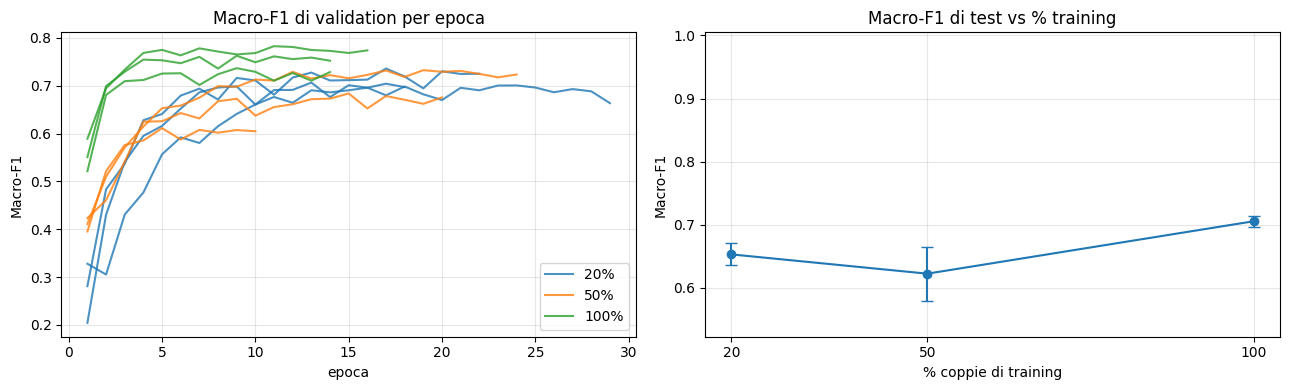

In [ ]:
COLORS = dict(zip(PERCENTAGES, ['tab:blue', 'tab:orange', 'tab:green']))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (pct, seed), h in histories.items():
    axes[0].plot(h.epoch, h.valid_macro_f1, color=COLORS[pct],
                 alpha=0.8, label=f'{pct}%' if seed == SEEDS[0] else None)
axes[0].set(title='Macro-F1 di validation per epoca', xlabel='epoca', ylabel='Macro-F1'); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].errorbar(summary.index, summary.test_f1_mean, yerr=summary.test_f1_std, marker='o', capsize=4)
axes[1].set(title='Macro-F1 di test vs % training', xlabel='% coppie di training', ylabel='Macro-F1',
            xticks=PERCENTAGES, ylim=(max(0, summary.test_f1_mean.min() - 0.1), 1.005)); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 9. Dove sbaglia: matrice di confusione e accuratezza per combinazione di semi (test, seed 0)

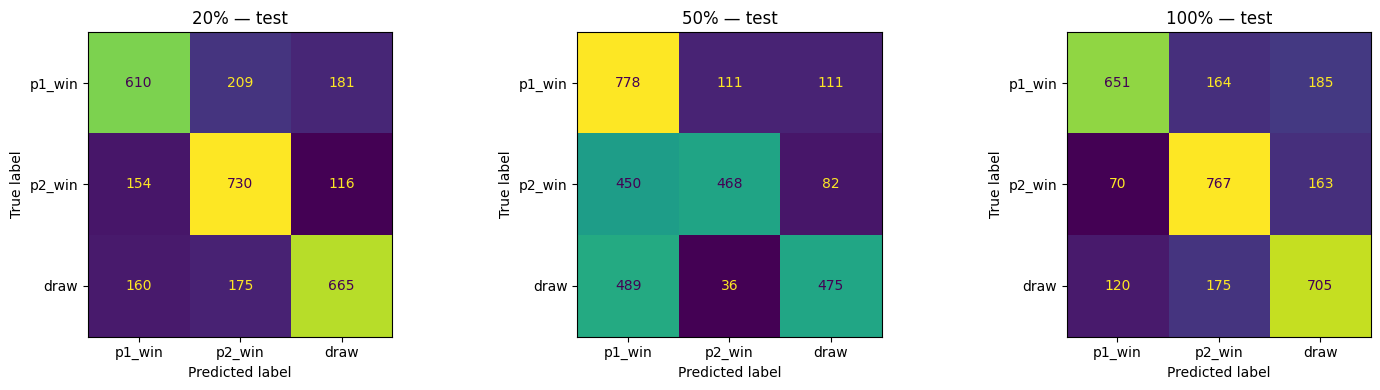

correct_100  correct_20  correct_50
s1     s2                                         
clubs  clubs         0.652       0.676       0.598
       hearts        0.790       0.706       0.619
       spades        0.658       0.541       0.814
hearts clubs         0.604       0.694       0.706
       hearts        0.883       0.748       0.820
       spades        0.787       0.811       0.787
spades clubs         0.725       0.674       0.000
       hearts        0.692       0.596       0.814
       spades        0.581       0.572       0.009

In [ ]:
test_df = pairs['test'].assign(s1=lambda d: d.first_image_id.map(suit_of), s2=lambda d: d.second_image_id.map(suit_of))
fig, axes = plt.subplots(1, len(PERCENTAGES), figsize=(5 * len(PERCENTAGES), 4))
for ax, pct in zip(np.atleast_1d(axes), PERCENTAGES):
    pred = test_preds[(pct, SEEDS[0])]
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=OUTCOMES).plot(ax=ax, colorbar=False)
    ax.set_title(f'{pct}% — test')
    test_df[f'correct_{pct}'] = (pred == y_test)
plt.tight_layout(); plt.show()

test_df.pivot_table(index=['s1', 's2'], values=[f'correct_{p}' for p in PERCENTAGES], aggfunc='mean').round(3)

## 10. Esempi di predizione dell'esito

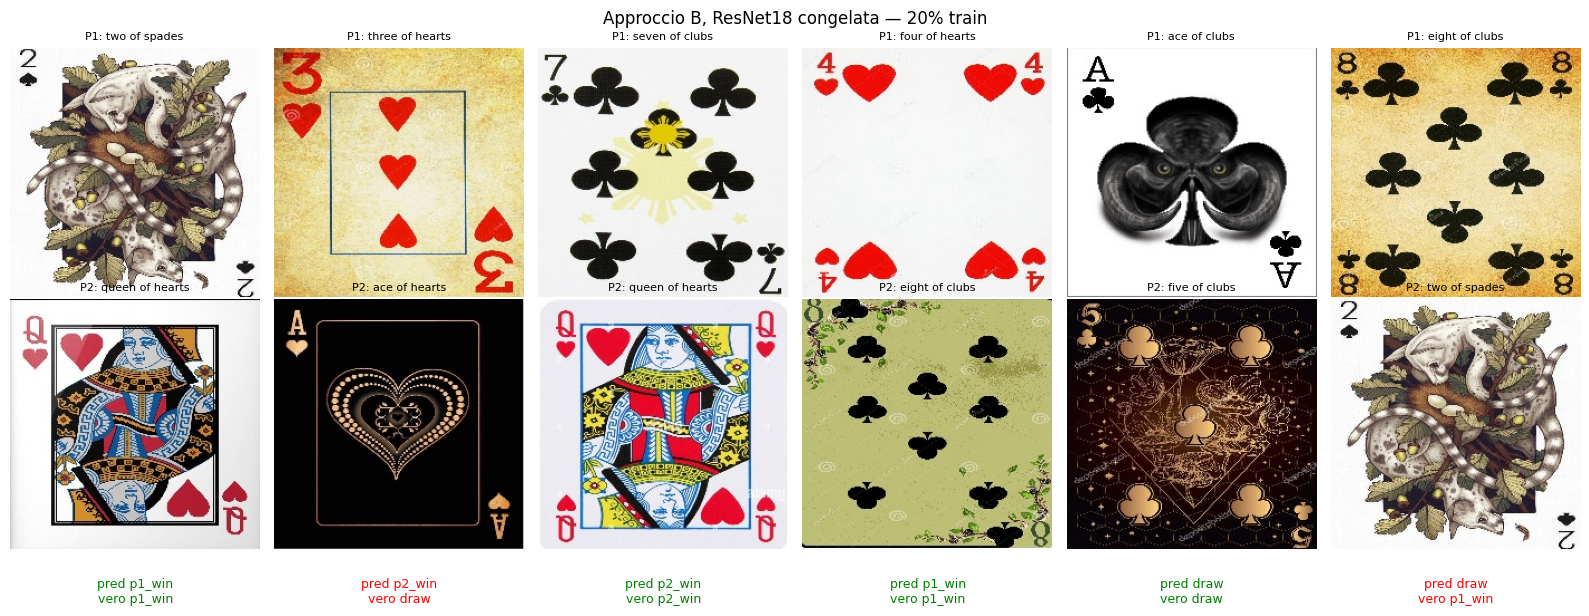

In [ ]:
model = models[(PERCENTAGES[0], SEEDS[0])]
rng = np.random.default_rng(0)
idx = rng.choice(len(test_df), 6, replace=False)
pred = test_preds[(PERCENTAGES[0], SEEDS[0])]
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for c, k in enumerate(idx):
    r = test_df.iloc[k]
    for row, iid in enumerate([r.first_image_id, r.second_image_id]):
        axes[row, c].imshow(IMAGES[ID2ROW[iid]].permute(1, 2, 0).numpy())
        axes[row, c].axis('off')
        axes[row, c].set_title(('P1: ' if row == 0 else 'P2: ') + iid.split('/')[1], fontsize=8)
    ok = OUTCOMES[pred[k]] == r.outcome
    axes[1, c].text(112, 250, f'pred {OUTCOMES[pred[k]]}\nvero {r.outcome}', ha='center', va='top',
                    color='green' if ok else 'red', fontsize=9)
plt.suptitle(f'Approccio B, ResNet18 congelata — {PERCENTAGES[0]}% train'); plt.tight_layout(); plt.show()

## 11. Diagnostica (non fa parte dell'Approccio B): le feature ImageNet separano già i semi?
Usa le **etichette dei semi**, che l'Approccio B non vede mai. Una regressione logistica lineare su una singola immagine (feature 512) → seme, allenata sulle immagini di train e valutata su quelle di test.
Se arriva vicino al 100%, la percezione è già quasi risolta dalle feature congelate, e resta da imparare soltanto la regola: 9 combinazioni.

In [ ]:
def suit_xy(split):
    ids = sorted(imgs[split])
    X = FEATS[[ID2ROW[i] for i in ids]].numpy()
    y = np.array([SUITS.index(suit_of(i)) for i in ids])
    return X, y

Xtr, ytr = suit_xy('train_100')
Xte, yte = suit_xy('test')
probe = LogisticRegression(max_iter=3000).fit(Xtr, ytr)
p = probe.predict(Xte)
print(f'Probe lineare sui semi — test acc {accuracy_score(yte, p):.4f}, macro-F1 {f1_score(yte, p, average="macro"):.4f}')
print(pd.DataFrame(confusion_matrix(yte, p), index=SUITS, columns=SUITS))

Probe lineare sui semi — test acc 0.8256, macro-F1 0.8263
        hearts  clubs  spades
hearts      57      2       6
clubs        3     52      10
spades       3     10      52


## 12. Come leggere i risultati
> Nota: questi criteri sono stati scritti **prima** di avere i risultati. L'esito del run (nessun effetto soffitto, Macro-F1 di test 0.62-0.71) e il confronto con la baseline di `feature/baseline` sono nel README `notebooks/README_approccio_B_resnet18_frozen.md`.

- **Test Macro-F1 ≥ ~0.97 già al 20%, con 20% ≈ 50% ≈ 100%** e probe lineare ≈ 100%: c'è **effetto soffitto**. La ResNet18 pre-addestrata è "troppo forte" per far emergere il vantaggio di DeepProbLog sull'accuratezza. Il confronto principale va fatto con un backbone piccolo allenato da zero, e la ResNet si tiene come ablation.
- **Distanza chiara tra 20% e 50%/100%**, oppure F1 lontana da 1: la baseline fatica ancora a imparare la regola o a generalizzare. C'è spazio perché DeepProbLog mostri un vantaggio anche con la ResNet.
- **Errori concentrati su alcune combinazioni** (tabella del §9): per esempio, se clubs/spades confusi dal probe causano errori nelle coppie che li contengono, il limite viene dalla percezione e non dalla regola.

**Tempi:** il training qui riguarda solo la testa (le feature sono pre-calcolate). Il costo totale è *estrazione feature + training testa*. Se confrontate con DeepProbLog usando lo stesso backbone congelato, potete usare lo stesso trucco anche lì, così il confronto resta equo.